# **Notebook 6: Fine-Tuning Pipeline**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `./tokenized_train/` + `./tokenized_valid/` — Created by Notebook 2
- [ ] GPU runtime enabled (T4 minimum)

**Files this notebook will CREATE:**
- [ ] `./intent_lora_best/` — Best LoRA checkpoint (by val loss) _(Required by NB7)_
- [ ] `./intent_lora/` — Final LoRA checkpoint _(Backup)_
- [ ] `training_log.csv` + `training_curves.png` — Evidence for report

---

## **Stage 4: Solution V2 (Fine-Tuned Retrieval-Assisted Generation)**

### **Task 4.1: Configure Fine-Tuning Pipeline**

#### **4.1.1 Configure PEFT Framework [3 marks]**
**The Task:** Apply LoRA (or QLoRA) to the model's `q_proj` and `v_proj` attention modules, set adapter settings and target modules, and prepare the training environment.

**Hints & Tips:**
* LoRA adds small trainable matrices to frozen attention layers — only ~0.5–1% of params update.
* `r=16` = rank of the low-rank matrices; `lora_alpha=32` scales them (rule of thumb: alpha = 2×r).
* `target_modules=["q_proj","v_proj"]`. Adding `["k_proj","o_proj"]` trains more params but may overfit on small data.
* Call `peft_model.print_trainable_parameters()` to confirm the tiny trainable %.

**LoRA Config Tuning:**
* `r`: 8 (lighter), **16 (recommended)**, 32 (more capacity).
* `lora_alpha`: usually 2×r → 16, **32**, 64.

**Learner Inference:** Updating only attention projections fundamentally changes behaviour (chat → JSON) using a fraction of the compute.

In [1]:
pip install -U "bitsandbytes>=0.46.1"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 46.3 MB/s eta 0:00:00:00:0100:01
Note: you may need to restart the kernel to use updated packages.


In [2]:
# YOUR CODE HERE
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model
from datasets import load_from_disk

# ── Config ───────────────────────────────────────────────
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
TRAIN_PATH = "/kaggle/input/datasets/piyushshx/artifacts/artifacts/tokenized_train"
VALID_PATH = "/kaggle/input/datasets/piyushshx/artifacts/artifacts/tokenized_valid"

# ── Load Tokenized Datasets ──────────────────────────────
train_dataset = load_from_disk(TRAIN_PATH)
valid_dataset = load_from_disk(VALID_PATH)
print(f"Train: {len(train_dataset)} | Valid: {len(valid_dataset)}")

# ── Load Model in 4-bit ──────────────────────────────────
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4"
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto"
)
print("Base model loaded ✅")

# ── Configure LoRA ───────────────────────────────────────
lora_config = LoraConfig(
    r=16,                              # rank
    lora_alpha=32,                     # scaling (2×r)
    target_modules=["q_proj", "v_proj"],  # attention layers only
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)

# Apply LoRA to model
peft_model = get_peft_model(model, lora_config)

# Confirm trainable parameters
peft_model.print_trainable_parameters()

Train: 3121 | Valid: 390


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Base model loaded ✅
trainable params: 2,179,072 || all params: 1,545,893,376 || trainable%: 0.1410


#### **4.1.2 Configure Training Parameters [2 marks]**
**The Task:** Define the learning rate, batch size, number of steps/epochs, optimisation strategy (AdamW), and quantisation settings.

**Hints & Tips:**
* Initialise `AdamW(filter(lambda p: p.requires_grad, peft_model.parameters()), lr=2e-4)`.
* Build `DataLoader`s for the train and validation sets (remember `set_format("torch", ...)` after `load_from_disk`).
* Define `VAL_EVERY` (e.g. 10 steps) and an early-stopping `PATIENCE` (e.g. 3) for the next task.

**Parameter Tuning:**
* `lr=2e-4` standard; try `1e-4` (slower) or `5e-4` (faster).
* `batch_size=4` fits T4; use 2 if OOM, 8 on A100.
* `max_steps=200`: ~25% of one epoch on 3200 rows. Increase to 400–500 for a full epoch.

**Learner Inference:** These hyperparameters control how fast and how stably the adapter learns the JSON-extraction task.

In [3]:
# YOUR CODE HERE
import torch
from torch.utils.data import DataLoader
from torch.optim import AdamW

# ── Set dataset format to torch tensors ─────────────────
train_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
valid_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])

# ── DataLoaders ──────────────────────────────────────────
BATCH_SIZE = 4

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train batches: {len(train_loader)}")
print(f"Valid batches: {len(valid_loader)}")

# ── Optimiser ────────────────────────────────────────────
optimizer = AdamW(
    filter(lambda p: p.requires_grad, peft_model.parameters()),
    lr=2e-4
)

# ── Training Config ──────────────────────────────────────
MAX_STEPS   = 200      # ~25% of one epoch on 3200 rows
VAL_EVERY   = 10       # validate every 10 steps
PATIENCE    = 3        # early stopping patience

print(f"Max steps:   {MAX_STEPS}")
print(f"Val every:   {VAL_EVERY} steps")
print(f"Patience:    {PATIENCE}")
print(f"Batch size:  {BATCH_SIZE}")
print(f"LR:          2e-4")
print("\nTraining parameters configured ✅")

Train batches: 781
Valid batches: 98
Max steps:   200
Val every:   10 steps
Patience:    3
Batch size:  4
LR:          2e-4

Training parameters configured ✅


### **Task 4.2: Train Fine-Tuned Model**

#### **4.2.1 Execute Fine-Tuning [5 marks]**
**The Task:** Run the custom PyTorch training loop. Monitor BOTH train and validation loss at regular intervals, implement early stopping based on validation loss, and plot the train-vs-validation loss curves.

**Hints & Tips:**
* The validation loop runs every `VAL_EVERY` steps under `torch.no_grad()` (no gradients).
* Early stopping: track `best_val_loss`; if it doesn't improve for `PATIENCE` checks, stop.
* The loss-curve plot is mandatory evidence — save it as `training_curves.png`.

**What to look for in the curve:**
* Both lines falling → learning, no overfitting.
* Val rises while train falls → overfitting (early stopping saves you).
* Both flat → LR too low or data too small.
* Val spikes → bad batch / instability.

**Learner Inference:** Falling loss proves gradient descent is teaching the JSON format. Validation monitoring prevents silent memorisation.

In [4]:
# YOUR CODE HERE
import os
import csv
import matplotlib.pyplot as plt
from tqdm import tqdm

# ── Output directories ───────────────────────────────────
os.makedirs("/kaggle/working/artifacts", exist_ok=True)
os.makedirs("/kaggle/working/intent_lora", exist_ok=True)
os.makedirs("/kaggle/working/intent_lora_best", exist_ok=True)

# ── Training loop ────────────────────────────────────────
best_val_loss    = float("inf")
patience_counter = 0
train_losses     = []
val_losses       = []
log_rows         = []
step             = 0

peft_model.train()
train_iter = iter(train_loader)

print("Starting training...\n")

while step < MAX_STEPS:
    # ── Get next batch (cycle through loader) ────────────
    try:
        batch = next(train_iter)
    except StopIteration:
        train_iter = iter(train_loader)
        batch = next(train_iter)

    # ── Train step ───────────────────────────────────────
    peft_model.train()
    input_ids      = batch["input_ids"].to(peft_model.device)
    attention_mask = batch["attention_mask"].to(peft_model.device)
    labels         = batch["labels"].to(peft_model.device)

    optimizer.zero_grad()
    outputs    = peft_model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
    train_loss = outputs.loss
    train_loss.backward()
    optimizer.step()

    step += 1

    # ── Validation every VAL_EVERY steps ─────────────────
    if step % VAL_EVERY == 0:
        peft_model.eval()
        val_loss_total = 0

        with torch.no_grad():
            for val_batch in valid_loader:
                v_input_ids      = val_batch["input_ids"].to(peft_model.device)
                v_attention_mask = val_batch["attention_mask"].to(peft_model.device)
                v_labels         = val_batch["labels"].to(peft_model.device)
                v_outputs        = peft_model(input_ids=v_input_ids, attention_mask=v_attention_mask, labels=v_labels)
                val_loss_total  += v_outputs.loss.item()

        avg_val_loss = val_loss_total / len(valid_loader)
        avg_train_loss = train_loss.item()

        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)
        log_rows.append({"step": step, "train_loss": avg_train_loss, "val_loss": avg_val_loss})

        print(f"Step {step:>4} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

        # ── Save best checkpoint ──────────────────────────
        if avg_val_loss < best_val_loss:
            best_val_loss    = avg_val_loss
            patience_counter = 0
            peft_model.save_pretrained("/kaggle/working/intent_lora_best")
            tokenizer.save_pretrained("/kaggle/working/intent_lora_best")
            print(f"  ✅ Best model saved (val_loss={best_val_loss:.4f})")
        else:
            patience_counter += 1
            print(f"  ⚠️  No improvement ({patience_counter}/{PATIENCE})")

        # ── Early stopping ────────────────────────────────
        if patience_counter >= PATIENCE:
            print(f"\nEarly stopping at step {step} — no improvement for {PATIENCE} checks.")
            break

Starting training...

Step   10 | Train Loss: 2.5050 | Val Loss: 2.4170
  ✅ Best model saved (val_loss=2.4170)
Step   20 | Train Loss: 1.1796 | Val Loss: 1.2023
  ✅ Best model saved (val_loss=1.2023)
Step   30 | Train Loss: 1.0350 | Val Loss: 0.9654
  ✅ Best model saved (val_loss=0.9654)
Step   40 | Train Loss: 1.0258 | Val Loss: 0.9041
  ✅ Best model saved (val_loss=0.9041)
Step   50 | Train Loss: 0.8149 | Val Loss: 0.8547
  ✅ Best model saved (val_loss=0.8547)
Step   60 | Train Loss: 1.0584 | Val Loss: 0.8027
  ✅ Best model saved (val_loss=0.8027)
Step   70 | Train Loss: 0.7605 | Val Loss: 0.7545
  ✅ Best model saved (val_loss=0.7545)
Step   80 | Train Loss: 0.7661 | Val Loss: 0.6943
  ✅ Best model saved (val_loss=0.6943)
Step   90 | Train Loss: 0.5148 | Val Loss: 0.6251
  ✅ Best model saved (val_loss=0.6251)
Step  100 | Train Loss: 0.6371 | Val Loss: 0.5742
  ✅ Best model saved (val_loss=0.5742)
Step  110 | Train Loss: 0.5761 | Val Loss: 0.5512
  ✅ Best model saved (val_loss=0.5512)

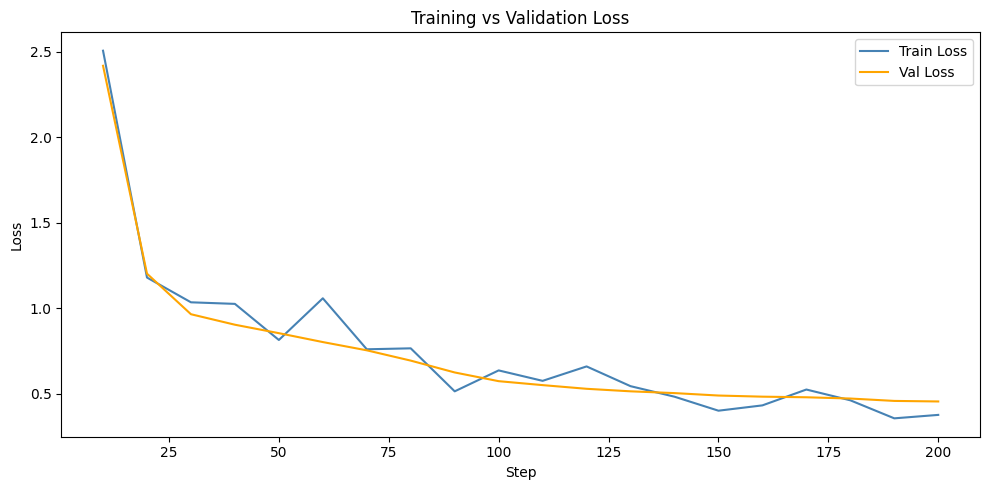

training_curves.png saved ✅


In [5]:
# YOUR CODE HERE
# ── Plot loss curves ─────────────────────────────────────
steps_logged = [r["step"] for r in log_rows]

plt.figure(figsize=(10, 5))
plt.plot(steps_logged, train_losses, label="Train Loss", color="steelblue")
plt.plot(steps_logged, val_losses,   label="Val Loss",   color="orange")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.savefig("/kaggle/working/artifacts/training_curves.png", dpi=150)
plt.show()
print("training_curves.png saved ✅")

#### **4.2.2 Save Training Outputs [2 marks]**
**The Task:** Save the best checkpoint (by validation loss), document the checkpoint/model-saving workflow, and export reproducibility information.

**Hints & Tips:**
* Save two checkpoints: `./intent_lora_best/` (lowest val loss) and `./intent_lora/` (final step).
* Export a `training_log.csv` with columns `step, train_loss, val_loss`.
* Record reproducibility info: model ID, LoRA config, learning rate, batch size, seed.

**Learner Inference:** Saving the BEST checkpoint (not the last) ensures your final model is the one that generalised best, not one that started overfitting.

In [7]:
import json

# Final checkpoint + training log (as before)
peft_model.save_pretrained("/kaggle/working/intent_lora")
tokenizer.save_pretrained("/kaggle/working/intent_lora")
print("Final checkpoint saved ✅")

with open("/kaggle/working/artifacts/training_log.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["step", "train_loss", "val_loss"])
    writer.writeheader()
    writer.writerows(log_rows)
print("training_log.csv saved ✅")

# Reproducibility record (printed in the notebook, no new file)
reproducibility = {
    "model_id":            MODEL_ID,
    "quantisation":        {"load_in_4bit": bnb_config.load_in_4bit,
                            "quant_type": bnb_config.bnb_4bit_quant_type,
                            "double_quant": bnb_config.bnb_4bit_use_double_quant,
                            "compute_dtype": str(bnb_config.bnb_4bit_compute_dtype)},
    "lora":                {"r": lora_config.r, "alpha": lora_config.lora_alpha,
                            "dropout": lora_config.lora_dropout,
                            "target_modules": sorted(lora_config.target_modules)},
    "optimizer":           "AdamW",
    "learning_rate":       optimizer.param_groups[0]["lr"],
    "lr_scheduler":        "none (constant LR)",
    "batch_size":          BATCH_SIZE,
    "max_steps":           MAX_STEPS,
    "val_every_steps":     VAL_EVERY,
    "early_stop_patience": PATIENCE,
    "stopped_at_step":     step,
    "best_val_loss":       round(best_val_loss, 4),
    "data_seed":           "42 (sampling and stratified splits)",
    "training_seed":       "not set (DataLoader shuffling and LoRA init are unseeded)",
}
print(json.dumps(reproducibility, indent=2))

Final checkpoint saved ✅
training_log.csv saved ✅
{
  "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
  "quantisation": {
    "load_in_4bit": true,
    "quant_type": "nf4",
    "double_quant": true,
    "compute_dtype": "torch.float16"
  },
  "lora": {
    "r": 16,
    "alpha": 32,
    "dropout": 0.05,
    "target_modules": [
      "q_proj",
      "v_proj"
    ]
  },
  "optimizer": "AdamW",
  "learning_rate": 0.0002,
  "lr_scheduler": "none (constant LR)",
  "batch_size": 4,
  "max_steps": 200,
  "val_every_steps": 10,
  "early_stop_patience": 3,
  "stopped_at_step": 200,
  "best_val_loss": 0.4557,
  "data_seed": "42 (sampling and stratified splits)",
  "training_seed": "not set (DataLoader shuffling and LoRA init are unseeded)"
}


In [8]:
import shutil

# Zip both folders
shutil.make_archive("/kaggle/working/intent_lora_best_zip", "zip", "/kaggle/working/intent_lora_best")
shutil.make_archive("/kaggle/working/intent_lora_zip", "zip", "/kaggle/working/intent_lora")

print("Zipped ✅")

Zipped ✅


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify before proceeding to Notebook 7.**

- [ ] Tokenized train/valid loaded from disk (`set_format` re-applied)
- [ ] **4.1.1** LoRA configured targeting `q_proj`/`v_proj`
- [ ] **4.1.2** Optimizer + training params + dataloaders set
- [ ] **4.2.1** Training loop run with val monitoring + early stopping + loss curve
- [ ] **4.2.2** Best checkpoint saved + reproducibility info recorded
- [ ] **`./intent_lora_best/` saved** ← _CRITICAL for NB7_
- [ ] **`training_log.csv` + `training_curves.png` saved** ← _Evidence_

**If any item is unchecked, fix it before moving on.**